# Finance challenge
## Six real U.S. industry portfolios and three checkable quantum contributions

This reference notebook uses **observed monthly value-weighted total returns** from Kenneth French's 10 Industry Portfolios. The six columns are **NoDur, Manuf, Enrgy, HiTec, Hlth and Utils**. They are research portfolios of U.S. listed shares, not ETF tickers or European assets. There is no asset-price prediction here.

**Decision date:** 31 December 2019. **Estimation:** January 2015–December 2019, 60 months. **Later evaluation:** January 2020–December 2024, 60 months. No later observation enters the initial estimates or quantum risk distribution. Selecting this retrospective teaching period is not a prospective investment experiment.

Choose a contribution: evaluate fixed-portfolio risk with iterative quantum amplitude estimation; justify and design a reversible circuit for decision conditions; or model binary allocation through QUBO/QAOA. The notebook demonstrates all three as a verified organiser reference. Teams are not expected to reproduce all three.

### Run
Use Python 3.12, install `requirements.txt`, open this notebook and **Restart Kernel → Run All**. Execution uses local simulation, no credentials, hardware or paid compute. The six-industry snapshot and helpers are embedded, so the notebook can also run without companion files once dependencies are installed. If companion data is present, its checksum is verified. The complete ZIP retains the original downloaded source files.

### Source
[Official monthly CSV ZIP](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/10_Industry_Portfolios_CSV.zip) · [Construction](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_ind_port.html) · [Industry definitions](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/Siccodes10.zip). Source units are percent; this notebook uses decimal returns. The official file contains multiple tables: only **Average Value Weighted Returns -- Monthly** is used. Retrieved 14 October 2026; the source identifies the 202608 CRSP database. Historical revisions are possible; use the frozen snapshot for this exercise.

In [1]:
import json, hashlib, io, time, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import importlib.metadata as metadata
START=time.perf_counter()
OUTPUT=Path('results');OUTPUT.mkdir(exist_ok=True)
CONFIG=json.loads('{\n  "industries": [\n    "NoDur",\n    "Manuf",\n    "Enrgy",\n    "HiTec",\n    "Hlth",\n    "Utils"\n  ],\n  "estimation_start": "2015-01",\n  "estimation_end": "2019-12",\n  "evaluation_start": "2020-01",\n  "evaluation_end": "2024-12",\n  "decision_date": "2019-12-31",\n  "starting_weights": [\n    0.3333333333333333,\n    0,\n    0,\n    0,\n    0.3333333333333333,\n    0.3333333333333333\n  ],\n  "candidate_cardinality": 3,\n  "change_penalty": 0.002,\n  "return_stress_hitec_shift": -0.005,\n  "covariance_stress_correlation_mix": 0.25,\n  "threshold_rebalance_absolute_drift": 0.05,\n  "mandates": {\n    "growth_oriented": {\n      "risk_coefficient": 1.0,\n      "loss_threshold": 0.08,\n      "breach_probability_tolerance": 0.1,\n      "hitec_weight_cap": 1.0\n    },\n    "balanced": {\n      "risk_coefficient": 5.0,\n      "loss_threshold": 0.05,\n      "breach_probability_tolerance": 0.1,\n      "hitec_weight_cap": 0.35\n    },\n    "risk_sensitive": {\n      "risk_coefficient": 20.0,\n      "loss_threshold": 0.03,\n      "breach_probability_tolerance": 0.1,\n      "hitec_weight_cap": 0.2\n    }\n  },\n  "scope": "Mandates, penalties, thresholds and caps are explicit organiser modelling choices, not facts supplied by Kenneth French or regulatory standards. Technology cap is a hypothetical investor concentration restriction; the dataset is not an ESG dataset."\n}')
MANIFEST=json.loads('{\n  "source_url": "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/10_Industry_Portfolios_CSV.zip",\n  "description_url": "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_ind_port.html",\n  "definitions_url": "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/Siccodes10.zip",\n  "retrieval_date_utc": "2026-10-14",\n  "source_header": "This file was created using the 202608 CRSP database.",\n  "section": "Average Value Weighted Returns -- Monthly",\n  "source_units": "percent",\n  "output_units": "decimal monthly total returns",\n  "rows": 120,\n  "columns": [\n    "NoDur",\n    "Manuf",\n    "Enrgy",\n    "HiTec",\n    "Hlth",\n    "Utils"\n  ],\n  "missing_handling": "Reject missing sentinels; no imputation",\n  "source_zip_sha256": "ebd937a4b995d821867aeb956a96f09a666386f38fa82516b7d1767ee4a49ae5",\n  "clean_csv_sha256": "083dbb4332bdea357f12fae310f7155624df12d14643e0eee574873586f811f5",\n  "copyright": "Eugene F. Fama and Kenneth R. French. Original files retained unchanged for provenance. Industry series are research portfolios, not directly tradable ETF tickers."\n}')
EMBEDDED_CSV='month,NoDur,Manuf,Enrgy,HiTec,Hlth,Utils\n2015-01,-0.00560000,-0.03750000,-0.04310000,-0.03460000,0.01580000,0.01240000\n2015-02,0.05130000,0.06150000,0.04720000,0.08220000,0.04000000,-0.04360000\n2015-03,-0.02420000,-0.02050000,-0.02490000,-0.02510000,0.00860000,-0.00310000\n2015-04,0.00810000,-0.00760000,0.06650000,0.01440000,-0.01550000,0.00280000\n2015-05,0.01500000,0.00880000,-0.05110000,0.01930000,0.04990000,-0.00430000\n2015-06,-0.01530000,-0.01990000,-0.03750000,-0.03590000,0.00370000,-0.05270000\n2015-07,0.04960000,-0.02010000,-0.08950000,0.02210000,0.03500000,0.02650000\n2015-08,-0.04100000,-0.05610000,-0.03650000,-0.05830000,-0.08380000,-0.04080000\n2015-09,-0.00560000,-0.04240000,-0.05750000,-0.01320000,-0.06920000,-0.00500000\n2015-10,0.06800000,0.09410000,0.12170000,0.10120000,0.07510000,0.02090000\n2015-11,-0.00920000,0.00410000,0.01060000,0.01150000,0.00580000,-0.03420000\n2015-12,0.00780000,-0.02540000,-0.09600000,-0.02520000,0.00320000,-0.02390000\n2016-01,0.00170000,-0.05710000,-0.04370000,-0.05960000,-0.10120000,0.04670000\n2016-02,0.00590000,0.03300000,-0.02950000,-0.00880000,-0.00970000,0.01720000\n2016-03,0.04960000,0.06910000,0.10890000,0.08490000,0.03950000,0.07840000\n2016-04,0.00270000,0.02290000,0.09170000,-0.04200000,0.04960000,-0.00800000\n2016-05,0.00740000,-0.00530000,-0.00590000,0.05140000,0.02420000,0.02240000\n2016-06,0.04740000,0.00910000,0.02550000,-0.01740000,-0.00170000,0.07430000\n2016-07,-0.00060000,0.04070000,-0.02730000,0.07530000,0.06160000,-0.00260000\n2016-08,-0.00610000,0.01400000,0.01610000,0.01790000,-0.03150000,-0.03780000\n2016-09,-0.02480000,-0.00020000,0.02810000,0.02220000,0.00600000,0.01830000\n2016-10,-0.00180000,-0.02550000,-0.02960000,-0.01120000,-0.07530000,-0.00660000\n2016-11,-0.03870000,0.06290000,0.09590000,0.00740000,0.02390000,-0.02650000\n2016-12,0.03460000,0.00490000,0.01970000,0.00920000,0.00690000,0.03610000\n2017-01,0.01690000,0.03340000,-0.04290000,0.04600000,0.02020000,0.01090000\n2017-02,0.03750000,0.04170000,-0.02460000,0.04840000,0.06970000,0.03850000\n2017-03,0.00880000,0.00130000,-0.01200000,0.02110000,0.00040000,0.00380000\n2017-04,0.00510000,0.01870000,-0.02730000,0.02550000,0.00930000,0.00320000\n2017-05,0.03220000,0.01270000,-0.03380000,0.04110000,-0.00270000,0.02440000\n2017-06,-0.01120000,0.01220000,-0.00140000,-0.02030000,0.05530000,-0.01910000\n2017-07,-0.00060000,0.02170000,0.02050000,0.03610000,0.00690000,0.02990000\n2017-08,-0.01750000,0.00330000,-0.05130000,0.03000000,0.02590000,0.02180000\n2017-09,-0.00380000,0.03940000,0.10940000,0.00600000,0.02080000,-0.01950000\n2017-10,0.00080000,0.02760000,0.00470000,0.06890000,-0.02250000,0.03020000\n2017-11,0.04070000,0.03470000,0.02990000,0.01060000,0.02480000,0.02420000\n2017-12,0.02010000,0.02280000,0.05000000,-0.00180000,-0.00160000,-0.04980000\n2018-01,0.01930000,0.04090000,0.02770000,0.07740000,0.06390000,-0.02810000\n2018-02,-0.06220000,-0.04030000,-0.10780000,-0.00010000,-0.03490000,-0.04540000\n2018-03,-0.01080000,-0.02240000,0.03070000,-0.03130000,-0.02390000,0.03170000\n2018-04,-0.03950000,-0.03420000,0.09930000,-0.00160000,-0.00050000,0.02780000\n2018-05,-0.00580000,0.02500000,0.03390000,0.06800000,0.02380000,0.00270000\n2018-06,0.04330000,-0.00980000,0.00500000,-0.00410000,0.01470000,0.02570000\n2018-07,0.02870000,0.05220000,0.01110000,0.02550000,0.05910000,0.01680000\n2018-08,-0.01160000,-0.00370000,-0.02840000,0.07150000,0.04500000,0.00930000\n2018-09,0.00710000,0.01250000,0.03370000,-0.00050000,0.02080000,-0.00570000\n2018-10,-0.00220000,-0.09790000,-0.11730000,-0.08820000,-0.08790000,-0.00060000\n2018-11,0.00490000,0.04680000,-0.02200000,-0.01580000,0.06410000,0.03260000\n2018-12,-0.11310000,-0.08700000,-0.13060000,-0.08220000,-0.08240000,-0.04770000\n2019-01,0.07290000,0.09660000,0.10340000,0.09300000,0.05310000,0.05380000\n2019-02,0.01340000,0.05200000,0.02470000,0.05660000,0.03300000,0.03550000\n2019-03,0.03670000,-0.00880000,0.02020000,0.03760000,0.00510000,0.03330000\n2019-04,0.03130000,0.04040000,0.00220000,0.05810000,-0.03160000,0.01000000\n2019-05,-0.05620000,-0.09170000,-0.11880000,-0.08540000,-0.03400000,-0.01550000\n2019-06,0.04910000,0.09200000,0.08830000,0.08010000,0.06820000,0.03640000\n2019-07,0.01600000,0.00970000,-0.02640000,0.03640000,-0.02160000,-0.01010000\n2019-08,-0.01420000,-0.01680000,-0.08510000,-0.02590000,-0.00640000,0.03450000\n2019-09,0.01880000,0.03840000,0.03690000,0.01290000,-0.00980000,0.03940000\n2019-10,0.00080000,0.00060000,-0.02080000,0.03280000,0.04660000,-0.01390000\n2019-11,0.02270000,0.03260000,0.01120000,0.05270000,0.05480000,-0.02140000\n2019-12,0.03480000,0.01340000,0.06240000,0.03840000,0.03450000,0.04120000\n2020-01,-0.00430000,-0.02740000,-0.11870000,0.03370000,-0.01990000,0.04830000\n2020-02,-0.08760000,-0.08610000,-0.15430000,-0.06990000,-0.05370000,-0.09890000\n2020-03,-0.10870000,-0.16910000,-0.34470000,-0.09770000,-0.05090000,-0.13050000\n2020-04,0.07750000,0.10860000,0.32310000,0.14920000,0.13450000,0.05180000\n2020-05,0.03100000,0.05820000,0.00560000,0.07630000,0.04160000,0.04630000\n2020-06,-0.00140000,0.02600000,-0.00390000,0.05730000,-0.01440000,-0.05020000\n2020-07,0.05870000,0.04560000,-0.04790000,0.06870000,0.04390000,0.06340000\n2020-08,0.04450000,0.06170000,-0.01140000,0.10620000,0.02350000,-0.02250000\n2020-09,-0.02080000,-0.00140000,-0.14990000,-0.05240000,-0.01430000,-0.00320000\n2020-10,-0.02700000,-0.00760000,-0.04460000,-0.01780000,-0.04370000,0.04470000\n2020-11,0.10020000,0.13960000,0.28530000,0.10720000,0.09830000,0.02660000\n2020-12,0.04910000,0.02520000,0.05690000,0.05080000,0.04710000,0.00620000\n2021-01,-0.04150000,-0.02320000,0.05050000,0.00560000,0.03420000,-0.00440000\n2021-02,0.01320000,0.05530000,0.23620000,0.01360000,-0.01250000,-0.04590000\n2021-03,0.07280000,0.07710000,0.02280000,0.00870000,-0.00090000,0.10390000\n2021-04,0.03320000,0.02440000,0.00750000,0.06420000,0.02960000,0.03980000\n2021-05,0.01970000,0.02770000,0.06200000,-0.00890000,-0.00120000,-0.01160000\n2021-06,-0.00810000,-0.01010000,0.05530000,0.06770000,0.04410000,-0.01420000\n2021-07,0.00230000,0.01330000,-0.08660000,0.03600000,0.02840000,0.02970000\n2021-08,-0.00280000,0.00550000,-0.01160000,0.04640000,0.02840000,0.03230000\n2021-09,-0.04580000,-0.05790000,0.11080000,-0.06140000,-0.06020000,-0.04870000\n2021-10,0.03740000,0.04990000,0.10270000,0.08140000,0.02230000,0.05110000\n2021-11,-0.03870000,-0.00690000,-0.05400000,0.01450000,-0.04260000,-0.01970000\n2021-12,0.08070000,0.05810000,0.03050000,0.01670000,0.06580000,0.08560000\n2022-01,-0.00650000,-0.05840000,0.17420000,-0.08430000,-0.08770000,-0.02100000\n2022-02,-0.00570000,-0.01230000,0.08360000,-0.04520000,-0.01010000,-0.01090000\n2022-03,0.00450000,0.00920000,0.09790000,0.03280000,0.05150000,0.09690000\n2022-04,0.02260000,-0.05290000,-0.01280000,-0.12600000,-0.06910000,-0.03710000\n2022-05,-0.01630000,-0.00370000,0.15570000,-0.02090000,0.00960000,0.04800000\n2022-06,-0.03890000,-0.09450000,-0.16550000,-0.08130000,-0.02020000,-0.06540000\n2022-07,0.04130000,0.08330000,0.10490000,0.11670000,0.02770000,0.06270000\n2022-08,-0.01820000,-0.03490000,0.03350000,-0.05370000,-0.05040000,0.00110000\n2022-09,-0.08370000,-0.11540000,-0.09250000,-0.11490000,-0.01920000,-0.11610000\n2022-10,0.09960000,0.12210000,0.23460000,0.05060000,0.08780000,0.03450000\n2022-11,0.05310000,0.09020000,0.01040000,0.05370000,0.05350000,0.06850000\n2022-12,-0.02630000,-0.02360000,-0.04240000,-0.07950000,-0.01720000,-0.01120000\n2023-01,-0.00370000,0.05920000,0.02750000,0.09580000,-0.01050000,-0.01220000\n2023-02,-0.02170000,-0.01850000,-0.06900000,-0.00200000,-0.04290000,-0.05320000\n2023-03,0.03170000,0.00370000,-0.00430000,0.10470000,0.02490000,0.03950000\n2023-04,0.03170000,-0.00590000,0.02580000,0.00240000,0.04120000,0.01720000\n2023-05,-0.05420000,-0.05540000,-0.09510000,0.08550000,-0.03660000,-0.05830000\n2023-06,0.02850000,0.10680000,0.06540000,0.05910000,0.04660000,0.02510000\n2023-07,0.02300000,0.03190000,0.07460000,0.04220000,-0.00120000,0.02770000\n2023-08,-0.03780000,-0.02380000,0.01970000,-0.01640000,-0.00230000,-0.05360000\n2023-09,-0.04600000,-0.07070000,0.03140000,-0.06020000,-0.04700000,-0.05050000\n2023-10,-0.03690000,-0.02700000,-0.06110000,-0.01770000,-0.04590000,0.01020000\n2023-11,0.04940000,0.08690000,-0.01340000,0.12060000,0.05800000,0.05150000\n2023-12,0.03570000,0.06330000,0.00170000,0.04620000,0.06910000,0.01730000\n2024-01,-0.01940000,-0.01160000,-0.00110000,0.03110000,0.03520000,-0.03010000\n2024-02,0.01690000,0.05330000,0.03090000,0.06220000,0.04630000,0.02390000\n2024-03,0.02960000,0.04480000,0.10290000,0.02360000,0.02190000,0.07040000\n2024-04,-0.01360000,-0.03930000,-0.00640000,-0.04410000,-0.05870000,0.01580000\n2024-05,0.00960000,0.03120000,-0.00450000,0.08100000,0.03200000,0.08030000\n2024-06,-0.02100000,-0.01900000,-0.02150000,0.07570000,0.02930000,-0.04160000\n2024-07,0.04770000,0.03430000,0.01990000,-0.01750000,0.00830000,0.06390000\n2024-08,0.04100000,0.01630000,-0.02920000,0.01350000,0.06410000,0.04580000\n2024-09,0.00980000,0.02500000,-0.03150000,0.02970000,-0.01840000,0.05340000\n2024-10,-0.02590000,-0.04020000,-0.00540000,-0.00220000,-0.03150000,0.00690000\n2024-11,0.01530000,0.06350000,0.06540000,0.04950000,-0.00510000,0.06210000\n2024-12,-0.05040000,-0.07810000,-0.08980000,0.01430000,-0.05380000,-0.07780000\n'

path=Path('data/returns_6_industries_monthly.csv')
raw=path.read_bytes() if path.exists() else EMBEDDED_CSV.encode()
assert hashlib.sha256(raw).hexdigest()==MANIFEST['clean_csv_sha256'], 'Frozen data changed; review provenance.'
returns=pd.read_csv(io.StringIO(raw.decode()),index_col='month',parse_dates=True)
assert list(returns.columns)==CONFIG['industries']
assert returns.shape==(120,6) and returns.index.is_unique and returns.index.is_monotonic_increasing
assert returns.index.equals(pd.date_range('2015-01-01','2024-12-01',freq='MS',name='month'))
assert np.isfinite(returns.to_numpy()).all() and (returns.to_numpy()>-1).all()
training=returns.loc['2015':'2019'].copy(); evaluation=returns.loc['2020':'2024'].copy()
assert len(training)==len(evaluation)==60 and training.index.max()<evaluation.index.min()
current=np.asarray(CONFIG['starting_weights'])
assert np.isclose(current.sum(),1) and (current>=0).all()
versions={p:metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','qiskit','qiskit-algorithms','nbformat','nbclient','ipykernel']}
print('Python',platform.python_version(), '\n',versions)
display(returns.head()); print('120 complete observations; no missing-value imputation.')


Python 3.12.14 
 {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'qiskit': '2.2.3', 'qiskit-algorithms': '0.4.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
120 complete observations; no missing-value imputation.


,NoDur,Manuf,Enrgy,HiTec,Hlth,Utils
month,,,,,,
2015-01-01,-0.0056,-0.0375,-0.0431,-0.0346,0.0158,0.0124
2015-02-01,0.0513,0.0615,0.0472,0.0822,0.0400,-0.0436
2015-03-01,-0.0242,-0.0205,-0.0249,-0.0251,0.0086,-0.0031
2015-04-01,0.0081,-0.0076,0.0665,0.0144,-0.0155,0.0028
2015-05-01,0.0150,0.0088,-0.0511,0.0193,0.0499,-0.0043


## 1. Financial meaning and assumptions

| Code | French industry grouping | Why included |
|---|---|---|
| NoDur | Consumer nondurables, including food, tobacco, textiles and apparel | Everyday-consumption exposure; **not** an automatic ethical label |
| Manuf | Machinery, trucks, aircraft, chemicals, paper and related manufacturing | Industrial exposure |
| Enrgy | Oil, gas and coal extraction and products | Concentrated energy exposure |
| HiTec | Computers, software and electronic equipment | Technology exposure |
| Hlth | Healthcare, medical equipment and drugs | Health-sector exposure |
| Utils | Utilities | Utility exposure |

The selection supplies interpretable sector contrasts; it is not a statistically optimal universe. Value weighting **inside each French industry portfolio** is different from our equal one-third weights **between selected industries**. Historical source returns are before any additional investor trading-cost assumptions. There is no EUR conversion. Liquidity, investor holdings, exclusions and institutional obligations are not supplied by French.

The starting allocation is **NoDur/Hlth/Utils, one third each**. This is a transparent organiser choice, not a reported real investor portfolio. The example proposed trade replaces NoDur with HiTec; both allocations are declared before later evaluation.

Three illustrative mandates provide separate parameters for selection, risk assessment and a technology exposure cap. These are teaching assumptions, not regulations or empirically estimated preferences. In the risk-sensitive mandate a **20% HiTec cap** makes a one-third technology position inadmissible. This creates a concrete conflict between higher estimated return and a binding exposure restriction. It is not an ESG rating or a claim that technology is irresponsible.

$R_{p,t}=\sum_i w_iR_{i,t}$; $\hat\mu_p=w^T\hat\mu$; $\hat\sigma_p^2=w^T\hat\Sigma w$. Here $R_{i,t}$ is industry $i$'s observed monthly decimal return, $w_i$ its portfolio weight, $\hat\mu$ the sample mean vector, and $\hat\Sigma$ the sample covariance with denominator $T-1$. Expected return means a historical estimate, not a forecast. One-way turnover is $\frac12\sum_i|w_i-w_i^{current}|$.

In [2]:
import itertools
import numpy as np
import pandas as pd

def scenario_sets(training, config):
    base = training.copy()
    shifted = base.copy()
    shifted['HiTec'] += config['return_stress_hitec_shift']
    mu = base.mean().to_numpy()
    sigma = base.cov().to_numpy()
    sd = np.sqrt(np.diag(sigma))
    rho = config['covariance_stress_correlation_mix']
    target = (1-rho)*sigma + rho*np.outer(sd,sd)
    def root(matrix, inverse=False):
        ev, vec = np.linalg.eigh(matrix)
        assert ev.min()>1e-12
        return (vec * (1/np.sqrt(ev) if inverse else np.sqrt(ev))) @ vec.T
    transformed=(base.to_numpy()-mu) @ root(sigma,True) @ root(target) + mu
    stressed=pd.DataFrame(transformed,index=base.index,columns=base.columns)
    assert np.allclose(stressed.mean(),mu,atol=1e-12)
    assert np.allclose(stressed.cov(),target,atol=1e-12)
    return {'base':base,'return_stress':shifted,'covariance_stress':stressed}

def decision_metrics(weights, outcomes, mandate, current, change_penalty):
    w=np.asarray(weights);r=outcomes.to_numpy() @ w
    mean=float(outcomes.mean() @ w)
    variance=float(w @ outcomes.cov().to_numpy() @ w)
    turnover=float(np.abs(w-current).sum()/2)
    loss_probability=float(np.mean(-r > mandate['loss_threshold']))
    return {'expected_monthly_return':mean,'monthly_variance':variance,
            'monthly_volatility':np.sqrt(variance),'turnover':turnover,
            'loss_breach_probability':loss_probability,
            'risk_condition':loss_probability<=mandate['breach_probability_tolerance']+1e-12,
            'technology_cap_condition':w[3]<=mandate['hitec_weight_cap']+1e-12,
            'score':mean-mandate['risk_coefficient']*variance-change_penalty*turnover}

def allocations(n=6,k=3):
    for ids in itertools.combinations(range(n),k):
        w=np.zeros(n);w[list(ids)]=1/k
        yield w

def portfolio_table(outcomes,mandate,current,config):
    records=[]
    for w in allocations():
        records.append({'holdings':'+'.join(outcomes.columns[w>0]),**decision_metrics(w,outcomes,mandate,current,config['change_penalty'])})
    return pd.DataFrame(records)

def replay_rule(returns,target,threshold=None):
    w=np.asarray(target,dtype=float).copy();wealth=1.;peak=1.;rows=[]
    for date,row in returns.iterrows():
        start=w.copy();port_return=float(start @ row.to_numpy())
        wealth*=1+port_return;peak=max(peak,wealth)
        before=start*(1+row.to_numpy())/(1+port_return)
        trigger=threshold is not None and np.max(abs(before-target))>threshold
        after=np.asarray(target).copy() if trigger else before.copy()
        turnover=float(abs(after-before).sum()/2)
        rows.append({'month':date,'portfolio_return':port_return,'wealth':wealth,
                     'drawdown':wealth/peak-1,'trade_trigger':bool(trigger),'turnover':turnover,
                     'max_target_drift_before_trade':float(max(abs(before-target))),
                     **{f'weight_after_{i}':float(x) for i,x in enumerate(after)}})
        w=after
    return pd.DataFrame(rows).set_index('month')


,risk_coefficient,loss_threshold,breach_probability_tolerance,hitec_weight_cap
mandate,,,,
growth_oriented,1.0,0.08,0.1,1.00
balanced,5.0,0.05,0.1,0.35
risk_sensitive,20.0,0.03,0.1,0.20


,mean_monthly,volatility_monthly
NoDur,0.006490,0.032225
Manuf,0.008625,0.041673
Enrgy,0.000242,0.060217
HiTec,0.015087,0.044896
Hlth,0.008685,0.042096
Utils,0.006795,0.030440


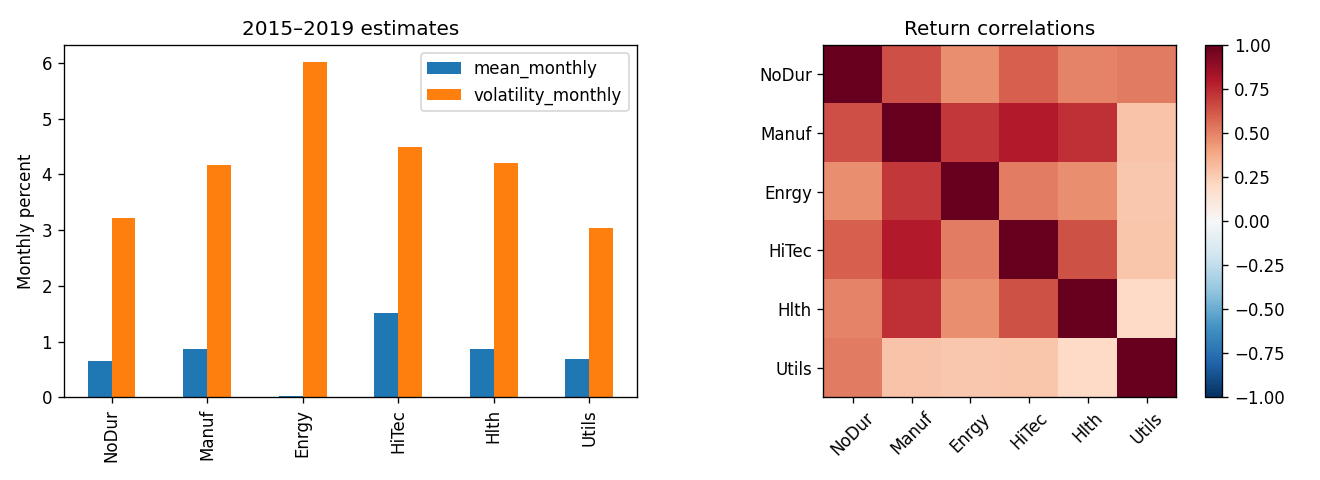

In [3]:
mandates=pd.DataFrame(CONFIG['mandates']).T
mandates.index.name='mandate';display(mandates)
scenarios=scenario_sets(training,CONFIG)
for name,r in scenarios.items():
    assert np.linalg.eigvalsh(r.cov()).min()>-1e-12
    r.mean().rename('expected_monthly_return').to_csv(OUTPUT/f'{name}_means.csv')
    r.cov().to_csv(OUTPUT/f'{name}_covariance.csv',index_label='industry')
    table=r.reset_index().rename(columns={'month':'source_month'})
    table.insert(0,'scenario_id',range(60)); table['probability']=1/60
    table.to_csv(OUTPUT/f'{name}_scenarios.csv',index=False,date_format='%Y-%m')
# Independent checks against the observed portfolio return vector.
rp=training.to_numpy() @ current
assert np.isclose(rp.mean(),training.mean() @ current)
assert np.isclose(rp.var(ddof=1),current @ training.cov().to_numpy() @ current)
stats=pd.DataFrame({'mean_monthly':training.mean(),'volatility_monthly':training.std(ddof=1)})
stats.to_csv(OUTPUT/'industry_estimates.csv');display(stats)
fig,axes=plt.subplots(1,2,figsize=(11,4))
(100*stats).plot.bar(ax=axes[0]);axes[0].set_ylabel('Monthly percent');axes[0].set_title('2015–2019 estimates')
image=axes[1].imshow(training.corr(),vmin=-1,vmax=1,cmap='RdBu_r');axes[1].set_xticks(range(6),returns.columns,rotation=45);axes[1].set_yticks(range(6),returns.columns);axes[1].set_title('Return correlations');fig.colorbar(image,ax=axes[1]);fig.tight_layout();fig.savefig(OUTPUT/'estimates_and_correlations.png',dpi=160);plt.show()


## 2. Base assumptions and two explicit stresses

- **Base:** all 60 joint monthly outcomes from 2015–2019, each with empirical probability 1/60. This preserves within-month cross-industry dependence. It is a one-month empirical model, not a calibrated future distribution; its 60 observations and temporal dependence limit inference.
- **Return stress:** subtract 0.005 (0.5 percentage points) from HiTec's return in each base scenario. Other industries are unchanged. This changes the technology mean and leaves the covariance unchanged.
- **Covariance stress:** move each pairwise correlation 25% towards +1 while keeping each industry's mean and variance fixed. The stressed covariance is $(1-\rho)\hat\Sigma+\rho ss^T$, with $\rho=0.25$ and $s$ the vector of sample standard deviations. It is positive semidefinite. A documented linear transformation of centred observations supplies a joint scenario table with this covariance.

**Both stress tables are hypothetical transformations, not additional observed French data.** Source-month identifiers trace the original observations; they do not make a transformed outcome historical. Neither stress is assigned a frequency of occurring in the real world. Their within-table probabilities remain empirical scenario weights.

Mean and covariance do not uniquely determine a probability distribution. We explicitly supply the full scenario tables. No outcome was clipped, independently resampled or selected to force a particular mandate result. The two stresses are pedagogical assumptions.

In [4]:
candidate=np.array([0,0,0,1/3,1/3,1/3])
financial_rows=[]
for name,r in scenarios.items():
    for mandate,m in CONFIG['mandates'].items():
        for allocation,w in [('retain',current),('replace_NoDur_with_HiTec',candidate)]:
            financial_rows.append({'scenario_set':name,'mandate':mandate,'allocation':allocation,**decision_metrics(w,r,m,current,CONFIG['change_penalty'])})
financial=pd.DataFrame(financial_rows);financial.to_csv(OUTPUT/'decision_sensitivity.csv',index=False)
display(financial[['scenario_set','mandate','allocation','expected_monthly_return','monthly_volatility','turnover','loss_breach_probability','risk_condition','technology_cap_condition']])
assert np.isclose(scenarios['return_stress'].mean()['HiTec']-training.mean()['HiTec'],-.005)
assert np.allclose(scenarios['return_stress'].cov(),training.cov())
# The higher-return proposal is actually higher in this frozen estimation sample.
assert training.mean() @ candidate > training.mean() @ current
assert candidate[3] > CONFIG['mandates']['risk_sensitive']['hitec_weight_cap']


,scenario_set,mandate,allocation,expected_monthly_return,monthly_volatility,turnover,loss_breach_probability,risk_condition,technology_cap_condition
0,base,growth_oriented,retain,0.007323,0.027112,0.000000,0.016667,True,True
1,base,growth_oriented,replace_NoDur_with_HiTec,0.010189,0.030510,0.333333,0.000000,True,True
2,base,balanced,retain,0.007323,0.027112,0.000000,0.033333,True,True
3,base,balanced,replace_NoDur_with_HiTec,0.010189,0.030510,0.333333,0.050000,True,True
4,base,risk_sensitive,retain,0.007323,0.027112,0.000000,0.083333,True,True
5,base,risk_sensitive,replace_NoDur_with_HiTec,0.010189,0.030510,0.333333,0.100000,True,False
6,return_stress,growth_oriented,retain,0.007323,0.027112,0.000000,0.016667,True,True
7,return_stress,growth_oriented,replace_NoDur_with_HiTec,0.008522,0.030510,0.333333,0.000000,True,True
8,return_stress,balanced,retain,0.007323,0.027112,0.000000,0.033333,True,True
9,return_stress,balanced,replace_NoDur_with_HiTec,0.008522,0.030510,0.333333,0.050000,True,True


## 3. Genuine quantum risk estimation

The encoded event is **one-month portfolio loss strictly greater than the mandate's loss threshold**, where loss is minus the portfolio return. The event threshold (3%, 5% or 8% loss) is distinct from the acceptable event probability (10%).

We use **six scenario qubits** to represent 60 observations; four unused basis states receive zero amplitude. **One event qubit** is flipped for scenario IDs whose losses exceed the threshold. The circuit has seven logical qubits; decomposition into a hardware gate basis can be much larger.

State preparation loads the square roots of the probabilities. The financial loss and marked scenario list are calculated outside the circuit and compiled into an event oracle. We are not claiming the circuit computes six-asset financial arithmetic from raw returns.

The algorithm is **iterative quantum amplitude estimation (IQAE)** from Qiskit Algorithms, with target half-width 0.01, alpha 0.05 and 2,048 shots per sampler call. It applies amplitude-amplification iterations; simple counting of sampled flags is not substituted for IQAE. Intervals address estimator sampling uncertainty **conditional on the encoded distribution**, not uncertainty about future market risk. They are per estimate; no simultaneous 95% guarantee over all runs is claimed.

References: [Woerner & Egger (2019)](https://arxiv.org/abs/1806.06893); [Grinko et al., iterative amplitude estimation](https://arxiv.org/abs/1912.05559); [Qiskit IQAE API](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.IterativeAmplitudeEstimation.html).

In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector,SparsePauliOp
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms import IterativeAmplitudeEstimation,EstimationProblem,QAOA
from qiskit_algorithms.optimizers import COBYLA

def risk_circuit(outcomes,weights,loss_threshold,probabilities=None):
    n=len(outcomes);size=1<<int(np.ceil(np.log2(n)));nq=int(np.log2(size))
    probabilities=np.ones(n)/n if probabilities is None else np.asarray(probabilities,dtype=float)
    assert len(probabilities)==n and np.all(probabilities>=0) and np.isclose(probabilities.sum(),1)
    padded=np.zeros(size);padded[:n]=probabilities
    losses=-(outcomes.to_numpy() @ weights);marked=np.flatnonzero(losses>loss_threshold)
    circuit=QuantumCircuit(nq+1,name='scenario_loss_event')
    circuit.append(StatePreparation(np.sqrt(padded)),list(range(nq)))
    for idx in marked:
        zero_controls=[q for q in range(nq) if not (int(idx)>>q)&1]
        for q in zero_controls:circuit.x(q)
        circuit.mcx(list(range(nq)),nq)
        for q in zero_controls:circuit.x(q)
    exact=float(probabilities[marked].sum())
    state=Statevector.from_instruction(circuit)
    assert np.isclose(state.probabilities([nq])[1],exact,atol=1e-12)
    marginal=state.probabilities(list(range(nq)))
    assert np.allclose(marginal,padded,atol=1e-12)
    return circuit,exact

def estimate_risk(outcomes,weights,threshold,seed=37):
    circuit,exact=risk_circuit(outcomes,weights,threshold)
    sampler=StatevectorSampler(default_shots=2048,seed=seed)
    algorithm=IterativeAmplitudeEstimation(epsilon_target=0.01,alpha=0.05,sampler=sampler)
    result=algorithm.estimate(EstimationProblem(state_preparation=circuit,objective_qubits=[circuit.num_qubits-1]))
    lo,hi=result.confidence_interval
    return {'exact_encoded_probability':exact,'estimated_probability':float(result.estimation),
            'interval_lower':float(lo),'interval_upper':float(hi),'absolute_error':float(abs(result.estimation-exact)),
            'oracle_queries':int(result.num_oracle_queries),'qubits':circuit.num_qubits,'grover_powers':list(result.powers)}

def condition_circuit():
    # q0 risk evidence, q1 concentration/policy, q2 evidence complete,
    # q3 temporary AND, q4 admissibility flag. q3/q4 initially zero.
    qc=QuantumCircuit(5,name='declared_conditions')
    qc.ccx(0,1,3);qc.ccx(3,2,4);qc.ccx(0,1,3)
    return qc

def verify_condition_circuit():
    qc=condition_circuit();rows=[]
    for bits in itertools.product([0,1],repeat=3):
        state=QuantumCircuit(5)
        for i,b in enumerate(bits):
            if b:state.x(i)
        state.compose(qc,inplace=True)
        v=Statevector.from_instruction(state);expected=int(all(bits))
        assert np.isclose(v.probabilities([4])[expected],1.)
        assert np.isclose(v.probabilities([3])[0],1.)
        for i,b in enumerate(bits):assert np.isclose(v.probabilities([i])[b],1.)
        rows.append({'risk_ok':bits[0],'policy_ok':bits[1],'evidence_complete':bits[2],'admissible':expected})
    return pd.DataFrame(rows)


In [6]:
risk_rows=[]
for scenario,r in scenarios.items():
    for mandate,m in CONFIG['mandates'].items():
        result=estimate_risk(r,current,m['loss_threshold'],seed=37)
        tolerance=m['breach_probability_tolerance']
        status='within_tolerance' if result['interval_upper']<=tolerance else ('breach' if result['interval_lower']>tolerance else 'unresolved_at_estimation_precision')
        risk_rows.append({'scenario_set':scenario,'mandate':mandate,'decision_from_estimator_interval':status,**result})
risk_results=pd.DataFrame(risk_rows);risk_results.to_csv(OUTPUT/'quantum_risk_results.csv',index=False)
display(risk_results)
qc,_=risk_circuit(training,current,.03)
print('Logical risk circuit qubits:',qc.num_qubits,'depth before hardware decomposition:',qc.depth())
print('Observed largest IQAE absolute error:',risk_results.absolute_error.max())
# This is a record of this seeded verification, not a mathematical guarantee of interval coverage.
coverage=((risk_results.exact_encoded_probability>=risk_results.interval_lower)&(risk_results.exact_encoded_probability<=risk_results.interval_upper)).tolist()
print('Encoded probabilities inside reported intervals:',coverage)
assert np.isfinite(risk_results.estimated_probability).all()
assert ((risk_results.estimated_probability>=0)&(risk_results.estimated_probability<=1)).all()
assert risk_results.absolute_error.max()<.03


Logical risk circuit qubits: 7 depth before hardware decomposition: 15
Observed largest IQAE absolute error: 0.0006757479945540129
Encoded probabilities inside reported intervals: [True, True, True, True, True, True, True, True, True]


,scenario_set,mandate,decision_from_estimator_interval,exact_encoded_probability,estimated_probability,interval_lower,interval_upper,absolute_error,oracle_queries,qubits,grover_powers
0,base,growth_oriented,within_tolerance,0.016667,0.016464,0.016063,0.016865,0.000203,18432,7,"[0, 0, 9]"
1,base,balanced,within_tolerance,0.033333,0.033356,0.032888,0.033825,0.000023,22528,7,"[0, 0, 11]"
2,base,risk_sensitive,within_tolerance,0.083333,0.084009,0.082895,0.085123,0.000676,14336,7,"[0, 0, 7]"
3,return_stress,growth_oriented,within_tolerance,0.016667,0.016464,0.016063,0.016865,0.000203,18432,7,"[0, 0, 9]"
4,return_stress,balanced,within_tolerance,0.033333,0.033356,0.032888,0.033825,0.000023,22528,7,"[0, 0, 11]"
5,return_stress,risk_sensitive,within_tolerance,0.083333,0.084009,0.082895,0.085123,0.000676,14336,7,"[0, 0, 7]"
6,covariance_stress,growth_oriented,within_tolerance,0.016667,0.016464,0.016063,0.016865,0.000203,18432,7,"[0, 0, 9]"
7,covariance_stress,balanced,within_tolerance,0.050000,0.050423,0.049652,0.051194,0.000423,16384,7,"[0, 0, 8]"
8,covariance_stress,risk_sensitive,within_tolerance,0.083333,0.084009,0.082895,0.085123,0.000676,14336,7,"[0, 0, 7]"


### A declared alternative, not an allocation search

Run IQAE for the specified NoDur-to-HiTec change under the same three scenario sets and mandates. This exposes the difference between a within-tolerance result, a breach and an interval overlapping the tolerance. No new portfolio is optimized. At exactly the 10% empirical tolerance, finite-estimation uncertainty may require reporting the decision as unresolved.

In [7]:
candidate_quantum_rows=[]
for scenario,r in scenarios.items():
    for mandate,m in CONFIG['mandates'].items():
        result=estimate_risk(r,candidate,m['loss_threshold'],seed=37)
        tolerance=m['breach_probability_tolerance']
        status='within_tolerance' if result['interval_upper']<=tolerance else ('breach' if result['interval_lower']>tolerance else 'unresolved_at_estimation_precision')
        candidate_quantum_rows.append({'allocation':'replace_NoDur_with_HiTec','scenario_set':scenario,'mandate':mandate,'decision_from_estimator_interval':status,**result})
proposal_quantum=pd.DataFrame(candidate_quantum_rows)
assert np.isfinite(proposal_quantum.estimated_probability).all()
assert proposal_quantum.absolute_error.max()<.03
risk_results['allocation']='retain'
risk_results=pd.concat([risk_results,proposal_quantum],ignore_index=True)
risk_results.to_csv(OUTPUT/'quantum_risk_results.csv',index=False)
display(proposal_quantum)
coverage=((risk_results.exact_encoded_probability>=risk_results.interval_lower)&(risk_results.exact_encoded_probability<=risk_results.interval_upper)).tolist()
print('Largest observed error over both declared allocations:',risk_results.absolute_error.max())


Largest observed error over both declared allocations: 0.000675747994554


,allocation,scenario_set,mandate,decision_from_estimator_interval,exact_encoded_probability,estimated_probability,interval_lower,interval_upper,absolute_error,oracle_queries,qubits,grover_powers
0,replace_NoDur_with_HiTec,base,growth_oriented,within_tolerance,0.000000,0.000002,0.000000,0.000003,0.000002,28672,7,"[0, 0, 14]"
1,replace_NoDur_with_HiTec,base,balanced,within_tolerance,0.050000,0.050423,0.049652,0.051194,0.000423,16384,7,"[0, 0, 8]"
2,replace_NoDur_with_HiTec,base,risk_sensitive,unresolved_at_estimation_precision,0.100000,0.099837,0.098781,0.100894,0.000163,16384,7,"[0, 0, 8]"
3,replace_NoDur_with_HiTec,return_stress,growth_oriented,within_tolerance,0.000000,0.000002,0.000000,0.000003,0.000002,28672,7,"[0, 0, 14]"
4,replace_NoDur_with_HiTec,return_stress,balanced,within_tolerance,0.050000,0.050423,0.049652,0.051194,0.000423,16384,7,"[0, 0, 8]"
5,replace_NoDur_with_HiTec,return_stress,risk_sensitive,breach,0.116667,0.116664,0.115748,0.117581,0.000002,20480,7,"[0, 0, 10]"
6,replace_NoDur_with_HiTec,covariance_stress,growth_oriented,within_tolerance,0.016667,0.016464,0.016063,0.016865,0.000203,18432,7,"[0, 0, 9]"
7,replace_NoDur_with_HiTec,covariance_stress,balanced,within_tolerance,0.066667,0.067072,0.066073,0.068071,0.000405,14336,7,"[0, 0, 7]"
8,replace_NoDur_with_HiTec,covariance_stress,risk_sensitive,breach,0.150000,0.150488,0.149052,0.151924,0.000488,14336,7,"[0, 0, 7]"


## 4. Analytical circuit design and a real conflict in the observed data

For the declared candidate, estimated return is higher than for retaining the current allocation. Yet its one-third technology weight violates the risk-sensitive investor's hypothetical 20% technology cap. Students must justify whether such a cap is a binding requirement, a negotiable preference or unsupported. A circuit cannot establish its legitimacy.

We demonstrate the smallest reversible building block, then require financial interpretation:
- q0: risk assessment passes the declared tolerance;
- q1: exposure restriction is satisfied;
- q2: evidence required for **this limited assessment** is available;
- q3: temporary working qubit, initially 0;
- q4: output flag, initially 0.

Two Toffoli operations combine the three conditions, and a third clears q3. All input qubits are preserved. The output means **admissible under these declared requirements**, not responsible in every sense or financially optimal.

Missing evidence is represented by q2=0 so admission is withheld; the accompanying decision record distinguishes **review needed** from **confirmed breach**. It is not silently assigned to satisfaction. A richer design could encode that distinction in separate flags. These flags are evaluated outside the circuit; calculating thresholds inside it would be a different implementation.

[IBM CCX/Toffoli documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.CCXGate); [Kop et al. (2024), responsibility principles](https://doi.org/10.1088/2058-9565/ad3776). The integration into a financial condition-design exercise is our teaching specification, not an established quantum responsibility measure.

{'case': 'missing supporting evidence', 'risk_ok': 1, 'policy_ok': 1, 'evidence_complete': 0, 'output': 0, 'interpretation': 'review needed; not a confirmed financial breach'}


,risk_ok,policy_ok,evidence_complete,admissible
0,0,0,0,0
1,0,0,1,0
2,0,1,0,0
3,0,1,1,0
4,1,0,0,0
5,1,0,1,0
6,1,1,0,0
7,1,1,1,1


,mandate,allocation,expected_monthly_return,risk_condition,technology_cap_condition,evidence_complete_for_encoded_case,admissible_under_declared_conditions
0,growth_oriented,retain,0.007323,True,True,True,True
1,growth_oriented,replace_NoDur_with_HiTec,0.010189,True,True,True,True
2,balanced,retain,0.007323,True,True,True,True
3,balanced,replace_NoDur_with_HiTec,0.010189,True,True,True,True
4,risk_sensitive,retain,0.007323,True,True,True,True
5,risk_sensitive,replace_NoDur_with_HiTec,0.010189,True,False,True,False


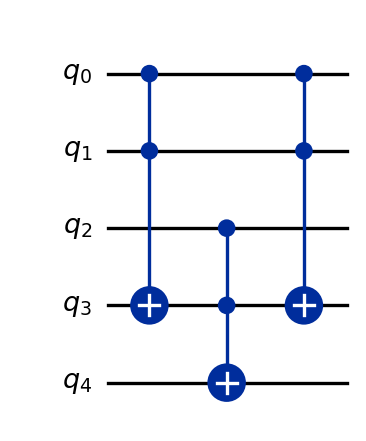

In [8]:
truth=verify_condition_circuit();display(truth)
truth.to_csv(OUTPUT/'condition_truth_table.csv',index=False)
fig=condition_circuit().draw(output='mpl',fold=-1)
fig.savefig(OUTPUT/'condition_circuit.png',dpi=160,bbox_inches='tight')
plt.show()
analytical=financial.loc[financial.scenario_set.eq('base'),['mandate','allocation','expected_monthly_return','risk_condition','technology_cap_condition']].copy()
analytical['evidence_complete_for_encoded_case']=True
analytical['admissible_under_declared_conditions']=analytical.risk_condition & analytical.technology_cap_condition
analytical.to_csv(OUTPUT/'analytical_cases.csv',index=False);display(analytical)
unknown={'case':'missing supporting evidence','risk_ok':1,'policy_ok':1,'evidence_complete':0,'output':0,'interpretation':'review needed; not a confirmed financial breach'}
print(unknown)


## 5. Optional allocation investigation and encoding verification

Select exactly three industries at equal one-third weights. The score is estimated monthly return minus a mandate-dependent variance penalty and a holdings-change penalty. The latter uses coefficient 0.002 per unit of one-way turnover and is a declared modelling preference, **not a measured transaction fee**. Risk coefficients are 1, 5 and 20; the data and parameters are identical throughout this notebook.

A one-third technology position is prohibited when it exceeds the supplied technology cap. QUBO penalties enforce cardinality and that restriction. Each penalty exceeds the **entire range of unpenalized financial energies over all 64 bitstrings**, so a global minimum cannot violate either condition. We verify all bitstrings and the Ising matrix diagonal; this is encoding validation, not a solver contest.

QAOA runs the base case under all three mandates, with two layers, three declared starting seeds (7, 19, 41), 4,096 shots per objective evaluation and a maximum of 100 COBYLA evaluations. The reported decision is the **most probable feasible measured bitstring**, not a guarantee of optimality. We report feasible probability mass and all sampled bitstrings. The notebook's full sensitivity table is available for financial investigation; extra QAOA stress runs are left as a clearly optional extension.

[Lucas (2014)](https://doi.org/10.3389/fphy.2014.00005); [Hadfield et al. (2019)](https://doi.org/10.3390/a12020034); [Qiskit QAOA API](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.QAOA.html).

In [9]:

def make_qubo(outcomes,mandate,current,config):
    mu=outcomes.mean().to_numpy();sigma=outcomes.cov().to_numpy();lam=mandate['risk_coefficient'];tau=config['change_penalty'];x0=(current>0).astype(float)
    # Equal weights w=x/3. One-way turnover = Hamming(x,x0)/6.
    d=-mu/3+lam*np.diag(sigma)/9+tau*(1-2*x0)/6
    upper=np.triu(2*lam*sigma/9,k=1);constant=tau*x0.sum()/6
    states=np.array([[int((i>>q)&1) for q in range(6)] for i in range(64)])
    f=constant+states@d+np.einsum('bi,ij,bj->b',states,upper,states)
    penalty=float(np.ptp(f)+0.001) # exceeds entire unconstrained financial energy range
    d=d-5*penalty;upper=upper+np.triu(np.ones((6,6))*2*penalty,k=1);constant+=9*penalty
    blocked=[3] if mandate['hitec_weight_cap']<1/3 else []
    for i in blocked:d[i]+=penalty
    costs=constant+states@d+np.einsum('bi,ij,bj->b',states,upper,states)
    valid=states.sum(axis=1)==3
    for i in blocked:valid &= states[:,i]==0
    assert valid.any() and valid[np.argmin(costs)]
    for index,x in enumerate(states):
        w=x/3;financial=-float(mu@w)+lam*float(w@sigma@w)+tau*float(abs(w-current).sum()/2)
        expected=financial+penalty*(int(x.sum())-3)**2+penalty*sum(x[i] for i in blocked)
        assert np.isclose(costs[index],expected,atol=1e-12)
    terms=[]
    def label(indices):
        s=['I']*6
        for i in indices:s[5-i]='Z'
        return ''.join(s)
    terms.append(('IIIIII',float(constant+d.sum()/2+upper.sum()/4)))
    for i in range(6):terms.append((label([i]),float(-d[i]/2-(upper[i,:].sum()+upper[:,i].sum())/4)))
    for i in range(6):
        for j in range(i+1,6):terms.append((label([i,j]),float(upper[i,j]/4)))
    hamiltonian=SparsePauliOp.from_list(terms).simplify()
    assert np.allclose(np.diag(hamiltonian.to_matrix()).real,costs,atol=1e-12)
    return {'operator':hamiltonian,'penalty':penalty,'costs':costs,'states':states,'valid':valid}

def run_qaoa(outcomes,mandate,current,config,seeds=(7,19,41)):
    model=make_qubo(outcomes,mandate,current,config);records=[];samples=[]
    scaled=model['operator']/model['penalty']
    for seed in seeds:
        initial=np.random.default_rng(seed).uniform(-np.pi,np.pi,4)
        alg=QAOA(sampler=StatevectorSampler(default_shots=4096,seed=seed),optimizer=COBYLA(maxiter=100),reps=2,initial_point=initial)
        result=alg.compute_minimum_eigenvalue(scaled)
        distribution=result.eigenstate
        probabilities={int(k,2) if isinstance(k,str) else int(k):float(v) for k,v in distribution.items()}
        feasible={i:p for i,p in probabilities.items() if model['valid'][i]}
        assert feasible
        selected=max(feasible,key=feasible.get);w=model['states'][selected]/3
        records.append({'seed':seed,'qubits':6,'qaoa_layers':2,'shots_per_evaluation':4096,'objective_evaluations':int(result.cost_function_evals),
                        'feasible_probability':sum(feasible.values()),'holdings':'+'.join(outcomes.columns[w>0]),
                        'selection_rule':'most probable feasible measured bitstring',**decision_metrics(w,outcomes,mandate,current,config['change_penalty'])})
        for idx,p in sorted(probabilities.items()):samples.append({'seed':seed,'bitstring_q5_to_q0':format(idx,'06b'),'probability':p,'feasible':bool(model['valid'][idx]),'financial_penalized_energy':float(model['costs'][idx])})
    return pd.DataFrame(records),pd.DataFrame(samples)


In [10]:
encoding_checks=0
for scenario,r in scenarios.items():
    for mandate,m in CONFIG['mandates'].items():
        make_qubo(r,m,current,CONFIG);encoding_checks+=64
all_portfolios=[]
for scenario,r in scenarios.items():
    for mandate,m in CONFIG['mandates'].items():
        table=portfolio_table(r,m,current,CONFIG)
        table.insert(0,'mandate',mandate);table.insert(0,'scenario_set',scenario)
        all_portfolios.append(table)
all_portfolios=pd.concat(all_portfolios,ignore_index=True);all_portfolios.to_csv(OUTPUT/'all_20_portfolios_sensitivity.csv',index=False)
qaoa_rows=[]
for mandate,m in CONFIG['mandates'].items():
    runs,samples=run_qaoa(training,m,current,CONFIG)
    runs.insert(0,'mandate',mandate);samples.insert(0,'mandate',mandate)
    qaoa_rows.append(runs);samples.to_csv(OUTPUT/f'qaoa_samples_{mandate}.csv',index=False)
qaoa_results=pd.concat(qaoa_rows,ignore_index=True);qaoa_results.to_csv(OUTPUT/'qaoa_results.csv',index=False)
display(qaoa_results[['mandate','seed','holdings','feasible_probability','expected_monthly_return','monthly_volatility','turnover']])
assert qaoa_results.technology_cap_condition.all()
print('Verified QUBO/Ising basis-state checks:',encoding_checks)


Verified QUBO/Ising basis-state checks: 576


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/codex/runtimes/codex-prim

,mandate,seed,holdings,feasible_probability,expected_monthly_return,monthly_volatility,turnover
0,growth_oriented,7,HiTec+Hlth+Utils,0.511719,0.010189,0.030510,0.333333
1,growth_oriented,19,NoDur+HiTec+Utils,0.368652,0.009457,0.028869,0.333333
2,growth_oriented,41,NoDur+Enrgy+Utils,0.775635,0.004509,0.032337,0.333333
3,balanced,7,HiTec+Hlth+Utils,0.589844,0.010189,0.030510,0.333333
4,balanced,19,HiTec+Hlth+Utils,0.403320,0.010189,0.030510,0.333333
5,balanced,41,NoDur+Enrgy+Utils,0.776855,0.004509,0.032337,0.333333
6,risk_sensitive,7,Manuf+Enrgy+Hlth,0.387451,0.005851,0.041629,0.666667
7,risk_sensitive,19,NoDur+Manuf+Enrgy,0.017822,0.005119,0.038732,0.666667
8,risk_sensitive,41,Manuf+Hlth+Utils,0.376465,0.008035,0.030227,0.333333


## 6. Later evaluation and avoiding a trade

Now open the separate 2020–2024 observations. This is historical evaluation, not an input to the initial decision. For each of the two declared allocations compare **retaining holdings with drifting weights** and **a prescribed-target rule**: inspect weights at each month-end, and restore the original target for the next month if any absolute deviation exceeds two or five percentage points. Both thresholds are declared illustrative settings; all six cases are retained, including a setting that causes no trades. No threshold optimization is performed. The technology alternative remains inadmissible under the risk-sensitive exposure cap; replaying it does not override that restriction.

Return is earned using weights held at the start of the month. Drift is calculated after that month's return, and any trade takes place afterwards. This avoids using end-of-month information to change beginning-of-month holdings. The simulation assumes no new cash, withdrawals, investor fees or taxes; returns are gross of any additional trading costs. Trading cost modelling is a possible extension and must not be inferred from the score penalty.

For an IQAE investigation of later data, say explicitly that it would be a **new information set**. Do not present a distribution built using these observations as one available on 31 December 2019.

,allocation,rule,terminal_wealth_per_initial_unit,worst_drawdown,trade_count,cumulative_one_way_turnover
0,retain_allocation,retain_holdings,1.381827,-0.169559,0,0.000000
1,retain_allocation,threshold_2pp,1.397905,-0.169559,8,0.209040
2,retain_allocation,threshold_5pp,1.381827,-0.169559,0,0.000000
3,declared_technology_alternative,retain_holdings,1.860040,-0.210409,0,0.000000
4,declared_technology_alternative,threshold_2pp,1.824478,-0.189452,18,0.447068
5,declared_technology_alternative,threshold_5pp,1.835509,-0.190040,3,0.175875


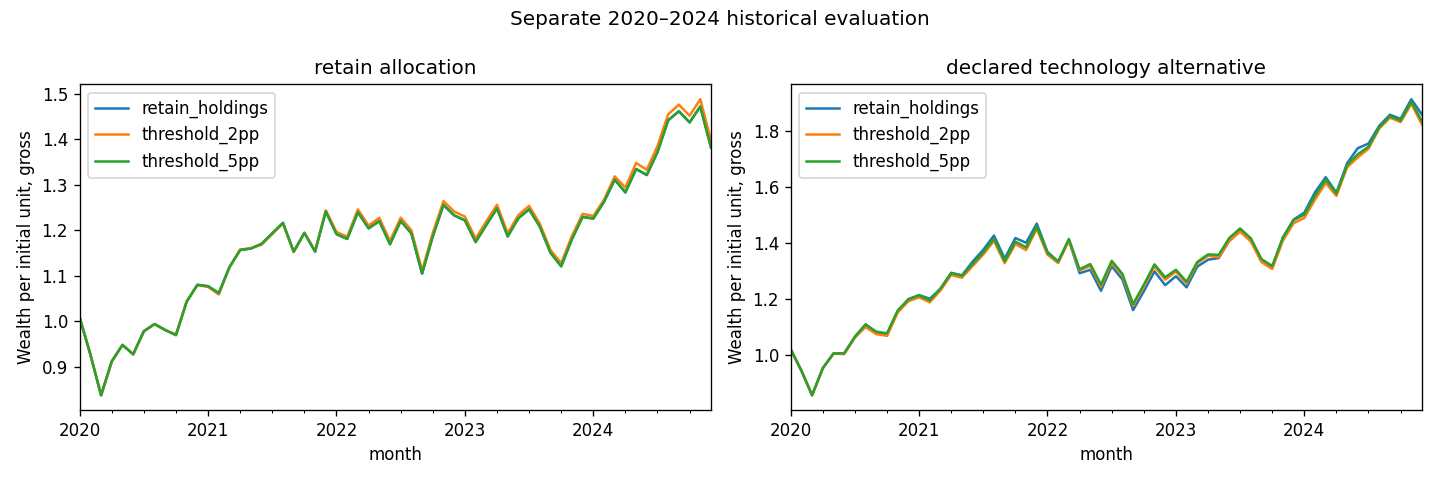

In [11]:
evaluation_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(allocation,target) in zip(axes,[('retain_allocation',current),('declared_technology_alternative',candidate)]):
    hold=replay_rule(evaluation,target)
    independent=(1+evaluation).cumprod().to_numpy() @ target
    assert np.allclose(hold.wealth,independent)
    variants=[('retain_holdings',None),('threshold_2pp',.02),('threshold_5pp',.05)]
    for rule_name,threshold in variants:
        frame=replay_rule(evaluation,target,threshold)
        assert np.allclose(frame.filter(like='weight_after_').sum(axis=1),1)
        assert (frame.filter(like='weight_after_')>=0).all().all()
        for idx in np.flatnonzero(frame.trade_trigger):
            assert np.allclose(frame.filter(like='weight_after_').iloc[idx],target)
            assert frame.max_target_drift_before_trade.iloc[idx]>threshold
        frame.to_csv(OUTPUT/f'{allocation}_{rule_name}_evaluation.csv',index_label='month')
        evaluation_rows.append({'allocation':allocation,'rule':rule_name,
              'terminal_wealth_per_initial_unit':float(frame.wealth.iloc[-1]),
              'worst_drawdown':float(frame.drawdown.min()),'trade_count':int(frame.trade_trigger.sum()),
              'cumulative_one_way_turnover':float(frame.turnover.sum())})
        frame.wealth.plot(ax=ax,label=rule_name)
    ax.set_title(allocation.replace('_',' '));ax.set_ylabel('Wealth per initial unit, gross');ax.legend()
summary=pd.DataFrame(evaluation_rows);summary.to_csv(OUTPUT/'rule_evaluation_summary.csv',index=False);display(summary)
fig.suptitle('Separate 2020–2024 historical evaluation');fig.tight_layout();fig.savefig(OUTPUT/'historical_rule_evaluation.png',dpi=160);plt.show()


## 7. What could reverse the decision?

Present two or three defensible alternatives if useful; ranking them by estimated return alone is insufficient. Identify the condition or evidence that would reverse your conclusion. Distinguish a requirement breach from insufficient evidence and a sensitive estimate.

The complete financial sensitivity table lets you investigate return, exposure, turnover and mandate restrictions. The quantum risk intervals may be too close to a tolerance to support an unambiguous decision; report that rather than forcing a verdict. An accepted logical output only establishes consistency with the encoded conditions.

This dataset contains no direct evidence about real investor obligations, liquidity, certification or ESG performance. The technology cap is a declared teaching restriction. Replacing it with a justified obligation is a substantive analytical contribution. A limitation of all work here is uncertainty about how historical estimates and empirical scenarios relate to future outcomes.

In [12]:
report={'status':'executed_without_cell_errors','python':platform.python_version(),'versions':versions,
        'data_shape':list(returns.shape),'training_months':60,'evaluation_months':60,
        'source_checksum_verified':True,'clean_csv_sha256':MANIFEST['clean_csv_sha256'],
        'financial_mean_variance_identity_verified':True,'covariance_stress_identity_verified':True,
        'condition_truth_table_cases_verified':len(truth),'condition_inputs_preserved_and_working_qubit_cleared':True,
        'qubo_ising_basis_states_verified':encoding_checks,'qaoa_runs':len(qaoa_results),
        'quantum_risk_runs':len(risk_results),'iqae_largest_observed_absolute_error':float(risk_results.absolute_error.max()),
        'iqae_interval_coverage_in_this_seeded_run':coverage,
        'drift_only_wealth_independent_identity_verified':True,
        'elapsed_notebook_seconds':time.perf_counter()-START,
        'scope':'Local ideal statevector simulation with finite-shot sampling. No hardware, noise model, investment validation or performance superiority claim.'}
(OUTPUT/'verification_report.json').write_text(json.dumps(report,indent=2))
print(json.dumps(report,indent=2))


{
  "status": "executed_without_cell_errors",
  "python": "3.12.14",
  "versions": {
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "scipy": "1.17.0",
    "matplotlib": "3.10.8",
    "qiskit": "2.2.3",
    "qiskit-algorithms": "0.4.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "pylatexenc": "2.10"
  },
  "data_shape": [
    120,
    6
  ],
  "training_months": 60,
  "evaluation_months": 60,
  "source_checksum_verified": true,
  "clean_csv_sha256": "083dbb4332bdea357f12fae310f7155624df12d14643e0eee574873586f811f5",
  "financial_mean_variance_identity_verified": true,
  "covariance_stress_identity_verified": true,
  "condition_truth_table_cases_verified": 8,
  "condition_inputs_preserved_and_working_qubit_cleared": true,
  "qubo_ising_basis_states_verified": 576,
  "qaoa_runs": 9,
  "quantum_risk_runs": 18,
  "iqae_largest_observed_absolute_error": 0.000675747994554,
  "iqae_interval_coverage_in_this_seeded_run": [
    true,
    true,
    true,
 